# Supervised autoencoder on the T = 32 benign (all 8 folders) + GridSybil windows (all/T32_benign_grid)

The ConvAutoencoder of `task/autoencoder_benign_t32/` (input 14 × 32 = 13 features + mask, z = 16, 63,293
parameters) with a small **classifier head on z** (Linear 16→32 → ReLU → Dropout 0.2 → Linear 32→1, 577 parameters;
63,870 in total). Loss = class-weighted BCE (`pos_weight` = n_benign / n_gridsybil of the **train** split) + λ ·
masked MSE on real rows (λ = `recon_weight` = 1). Data: `src/data/encoder_input/all/T32_benign_grid/`: benign windows
(sender never an attacker) from **all 8 scenario folders** + GridSybil attack windows from the 2 GridSybil folders, with
train / val / test = **85 / 7.5 / 7.5 by vehicle key** `<group>:<vehicle>` fixed on disk (⚠ RULE 3 new split).

Labels are used in training (supervised). The val split drives the LR schedule, early stopping, the best checkpoint
and both alarm thresholds (max F1 on val; benign FPR 5% on val). The test split is never read by `train.py`; here it
is read in section 4, and its labels only after every test window has been scored.

This notebook runs from the repo root, imports the package classes and reads the run folder written by
`npm run aest32:train`. Sections: 1 input, 2 model, 3 training record, 4 test, 5 comparison, 6 analysis. Not the
thesis TimesNet model.

Setup: repo-root check, package imports, the run folder (the newest `runs/*/summary.json`).

In [1]:
import json
import re
from pathlib import Path

assert Path("task/autoencoder_st_t32/config.py").is_file(), "run this notebook from the repo root"

from task.autoencoder_st_t32.config import SupervisedAEConfig, TOTAL_PARAMS
from task.autoencoder_st_t32.data import WindowDataset
from task.autoencoder_st_t32.metrics import TrackScores, ranking_metrics, threshold_metrics, val_thresholds
from task.autoencoder_st_t32.model import SupervisedAutoencoder, count_params
from task.autoencoder_st_t32.trainer import Trainer

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve

settings = SupervisedAEConfig()
runs = sorted(Path(settings.runs_dir).glob("*/summary.json"), key=lambda p: p.stat().st_mtime)
assert runs, "no finished run: npm run aest32:train"
RUN = runs[-1].parent
META = json.loads((Path(settings.data_dir) / "metadata.json").read_text())
FEATURES = META["features"]
print("run folder:", RUN)
print("data:", settings.data_dir)

run folder: task/autoencoder_st_t32/runs/seed0
data: src/data/encoder_input/all/T32_benign_grid


## 1. Input

The three splits as written on disk. Vehicle keys never cross splits (checked below). Class counts per split from the
data for train and val; test labels are not read in this section (its class counts are shown from `metadata.json`
only, as written by the pipeline). Every track (one link = one receiver hearing one sender pseudonym) has one label
(checked on train / val).

In [2]:
load = dict(workers=settings.workers, cache_dir=settings.cache_dir)
splits = {name: WindowDataset.load(settings.data_dir, name, **load) for name in ("train", "val", "test")}
train, val, test = splits["train"], splits["val"], splits["test"]
veh = {name: set(d.vehicles) for name, d in splits.items()}
assert not (veh["train"] & veh["val"]) and not (veh["train"] & veh["test"]) and not (veh["val"] & veh["test"])
tracks = {name: TrackScores(d.tracks) for name, d in splits.items()}
rows = []
for name in ("train", "val"):
    d = splits[name]
    for cls, v in (("Benign", 0), ("GridSybil", 1)):
        s = d.y == v
        rows.append(
            {
                "split": name,
                "class": cls,
                "windows": int(s.sum()),
                "messages": int(d.n_messages[s].sum()),
                "tracks": len(set(d.tracks[s])),
                "vehicle keys": len(set(d.vehicles[s])),
            }
        )
counts = pd.DataFrame(rows).pivot(index="split", columns="class").loc[["train", "val"]]
counts[("windows", "total")] = counts["windows"].sum(axis=1)
print("no vehicle key in two splits:", True)
print("tracks with mixed labels:", {name: tracks[name].track_labels(splits[name].y)[1] for name in ("train", "val")})
print(
    f"test (labels not read here): {len(test):,} windows, {len(tracks['test']):,} tracks, "
    f"{len(veh['test']):,} vehicle keys"
)
counts

no vehicle key in two splits: True
tracks with mixed labels: {'train': 0, 'val': 0}
test (labels not read here): 67,100 windows, 54,102 tracks, 524 vehicle keys


windows           messages            tracks           vehicle keys  \
class  Benign GridSybil   Benign GridSybil  Benign GridSybil       Benign   
split                                                                       
train  535501    243586  8903172   3749492  428277    194026         4465   
val     47279     20303   786677    301888   37689     16715          395   

                windows  
class GridSybil   total  
split                    
train      1468  779087  
val         129   67582

Split rule and per-split class counts as recorded by the pipeline in `metadata.json` (test included).

In [3]:
print(json.dumps({k: v for k, v in META.get("split", {}).items() if k != "vehicle_ids"}, indent=1))
for key in ("counts_by_split", "counts_by_split_class", "class_balance"):
    if key in META:
        print(f"\n{key}:")
        print(json.dumps(META[key], indent=1)[:2000])

{
 "key": "<group>:<sender vehicle> (the T24 notebook's key): one split per key across all 4 families",
 "class_of_vehicle": "the set of known attack codes the key carries over the 4 families (-1 ignored)",
 "rule": "strata = (group, class of the vehicle), sorted; sorted keys shuffled by one numpy default_rng(0) drawn stratum after stratum; test = first max(1, round(0.075 n)), val = next max(1, round(0.075 n)), train = rest (the T48_tvt / T32_benign rule)",
 "per_stratum": {
  "0709/Benign": {
   "train": 3462,
   "val": 306,
   "test": 306,
   "total": 4074
  },
  "0709/DataReplaySybil+DoSRandomSybil+DoSDisruptiveSybil": {
   "train": 447,
   "val": 40,
   "test": 40,
   "total": 527
  },
  "0709/GridSybil": {
   "train": 447,
   "val": 39,
   "test": 39,
   "total": 525
  },
  "0709/GridSybil+DataReplaySybil+DoSRandomSybil+DoSDisruptiveSybil": {
   "train": 590,
   "val": 52,
   "test": 52,
   "total": 694
  },
  "1416/Benign": {
   "train": 1006,
   "val": 89,
   "test": 89,
   "tot

Split diagram: windows per split (benign + GridSybil for train / val; test as one bar), with the vehicle keys behind each split.

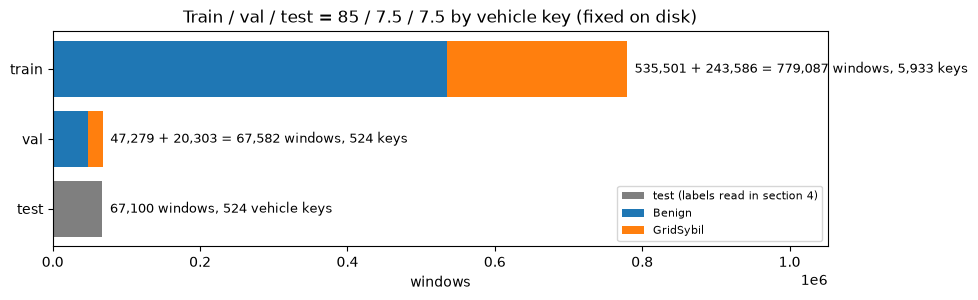

In [4]:
fig, ax = plt.subplots(figsize=(10, 2.8))
top = len(train) * 1.35
ax.barh(0, len(test), color="tab:grey", label="test (labels read in section 4)")
ax.text(len(test) + top * 0.01, 0, f"{len(test):,} windows, {len(veh['test']):,} vehicle keys", va="center", fontsize=9)
for y, name in ((1, "val"), (2, "train")):
    b, g = counts.loc[name, ("windows", "Benign")], counts.loc[name, ("windows", "GridSybil")]
    ax.barh(y, b, color="tab:blue", label="Benign" if y == 1 else None)
    ax.barh(y, g, left=b, color="tab:orange", label="GridSybil" if y == 1 else None)
    ax.text(
        b + g + top * 0.01, y, f"{b:,} + {g:,} = {b + g:,} windows, {len(veh[name]):,} keys", va="center", fontsize=9
    )
ax.set_yticks(range(3), ["test", "val", "train"])
ax.set_xlim(0, top)
ax.set_xlabel("windows")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Train / val / test = 85 / 7.5 / 7.5 by vehicle key (fixed on disk)")
plt.show()

Train / val windows per scenario folder and class: benign windows come from every folder, GridSybil only from the two
GridSybil folders. The same benign traffic recurs in the four families of one period (F1), so the benign set holds
about four copies of each period's traffic.

In [5]:
fam = (
    pd.concat(
        [
            pd.crosstab(np.asarray(d.info["scenario"]), np.where(d.y == 1, "GridSybil", "Benign")).add_prefix(f"{n} ")
            for n, d in (("train", train), ("val", val))
        ],
        axis=1,
    )
    .fillna(0)
    .astype(int)
)
fam.loc["total"] = fam.sum()
fam

col_0,train Benign,train GridSybil,val Benign,val GridSybil
row_0,,,,
DataReplaySybil_0709,108840,0,9879,0
DataReplaySybil_1416,24949,0,2158,0
DoSDisruptiveSybil_0709,108833,0,9896,0
DoSDisruptiveSybil_1416,24988,0,2161,0
DoSRandomSybil_0709,108833,0,9896,0
DoSRandomSybil_1416,24988,0,2161,0
GridSybil_0709,109116,193850,8965,16314
GridSybil_1416,24954,49736,2163,3989
total,535501,243586,47279,20303


Shape and padding: each window is 32 messages (1 Hz) × 13 normalised features, padding rows zero, the mask marks real
rows; the model gets the mask as a 14th channel (**14 × 32**). Padding and the share of 1–3-row windows per split
(per class for train / val). The class weight of the BCE comes from the train counts.

window x: (32, 13) + mask: (32,) -> model input: (14, 32)


windows  median rows  mean rows  share = 32  share 1-3 rows  \
split class                                                                    
train all         779087         14.0      16.24       0.211           0.152   
      Benign      535501         15.0      16.63       0.210           0.137   
      GridSybil   243586         13.0      15.39       0.211           0.185   
val   all          67582         14.0      16.11       0.205           0.158   
      Benign       47279         15.0      16.64       0.213           0.140   
      GridSybil    20303         12.0      14.87       0.186           0.200   
test  all          67100         14.0      15.93       0.203           0.158   

                 padding share  
split class                     
train all                0.492  
      Benign             0.480  
      GridSybil          0.519  
val   all                0.497  
      Benign             0.480  
      GridSybil          0.535  
test  all                0.502

pos_weight = n_benign / n_gridsybil (train) = 535,501 / 243,586 = 2.1984  (run: 2.1984); GridSybil share of train 0.313


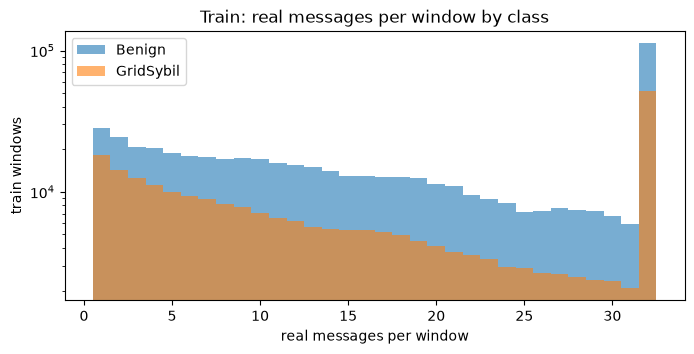

In [6]:
print(
    "window x:",
    train.x.shape[1:],
    "+ mask:",
    train.mask.shape[1:],
    "-> model input:",
    (settings.n_features + 1, settings.seq_len),
)
rows = []
for name, d in splits.items():
    groups = [("all", np.ones(len(d), bool))]
    if name != "test":
        groups += [("Benign", d.y == 0), ("GridSybil", d.y == 1)]
    for cls, s in groups:
        n = d.n_messages[s]
        rows.append(
            {
                "split": name,
                "class": cls,
                "windows": int(s.sum()),
                "median rows": np.median(n),
                "mean rows": round(n.mean(), 2),
                "share = 32": round(float((n == 32).mean()), 3),
                "share 1-3 rows": round(float((n <= 3).mean()), 3),
                "padding share": round(1 - d.mask[s].mean(), 3),
            }
        )
display(pd.DataFrame(rows).set_index(["split", "class"]))
n_b, n_g = int((train.y == 0).sum()), int((train.y == 1).sum())
pos_weight = n_b / n_g
summary = json.loads((RUN / "summary.json").read_text())
print(
    f"pos_weight = n_benign / n_gridsybil (train) = {n_b:,} / {n_g:,} = {pos_weight:.4f}  "
    f"(run: {summary['pos_weight']:.4f}); GridSybil share of train {n_g / (n_b + n_g):.3f}"
)
assert np.isclose(pos_weight, summary["pos_weight"])

fig, ax = plt.subplots(figsize=(8, 3.5))
for v, name in ((0, "Benign"), (1, "GridSybil")):
    ax.hist(train.n_messages[train.y == v], bins=np.arange(1, 34) - 0.5, alpha=0.6, label=name)
ax.set_xlabel("real messages per window")
ax.set_ylabel("train windows")
ax.set_yscale("log")
ax.legend()
ax.set_title("Train: real messages per window by class")
plt.show()

## 2. Model

Layers with their output shapes for one batch of 2 windows, including the classifier head, and the trainable
parameter count (asserted against 63,870 = 63,293 + 577).

In [7]:
model = SupervisedAutoencoder(settings)
x0, m0 = torch.zeros(2, settings.seq_len, settings.n_features), torch.ones(2, settings.seq_len, dtype=torch.bool)
table = []
layer_types = (torch.nn.Conv1d, torch.nn.ConvTranspose1d, torch.nn.Linear, torch.nn.Dropout)
hooks = [
    mod.register_forward_hook(
        lambda mod, inp, out, name=name: table.append(
            (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))
        )
    )
    for name, mod in model.named_modules()
    if isinstance(mod, layer_types)
]
model.eval()
with torch.no_grad():
    recon0, z0, logit0 = model(x0, m0)
for h in hooks:
    h.remove()
display(pd.DataFrame(table, columns=["layer", "type", "output (per window)", "params"]))
print("reconstruction:", tuple(recon0.shape[1:]), " z:", tuple(z0.shape[1:]), " logit:", tuple(logit0.shape[1:]))
print(
    f"trainable parameters: {count_params(model):,} = autoencoder {count_params(model.autoencoder):,} "
    f"+ head {count_params(model.head):,}"
)
assert count_params(model) == TOTAL_PARAMS == summary["params"] == 63_870

,layer,type,output (per window),params
0,autoencoder.encoder_conv.0,Conv1d,"(32, 32)",1376
1,autoencoder.encoder_conv.3,Conv1d,"(64, 16)",6208
2,autoencoder.encoder_conv.6,Conv1d,"(64, 8)",12352
3,autoencoder.to_z,Linear,"(16,)",8208
4,autoencoder.from_z,Linear,"(512,)",8704
5,autoencoder.decoder_conv.1,ConvTranspose1d,"(64, 16)",16448
6,autoencoder.decoder_conv.4,ConvTranspose1d,"(32, 32)",8224
7,autoencoder.decoder_conv.7,Conv1d,"(13, 32)",1261
8,head.net.0,Linear,"(32,)",544
9,head.net.2,Dropout,"(32,)",0


reconstruction: (32, 13)  z: (16,)  logit: ()
trainable parameters: 63,870 = autoencoder 63,293 + head 577


## 3. Training record

What `task.autoencoder_st_t32.train` wrote: the summary (without the threshold tables), the per-epoch history
re-plotted (losses train vs val; val AUROC / PR-AUC / F1 / balanced accuracy; LR and gradient norm), and log lines.
Train metrics are computed from the running epoch outputs (train mode: dropout on, weights changing within the epoch),
so train and val metrics are not strictly comparable.

{
  "run_id": "seed0",
  "params": 63870,
  "best_epoch": 17,
  "best_val_auroc": 0.9220063541523253,
  "epochs_run": 27,
  "stop_reason": "early_stopping",
  "lr_changes": [
    {
      "after_epoch": 23,
      "from": 0.001,
      "to": 0.0005
    }
  ],
  "train_seconds": 335.2,
  "train_windows": 779087,
  "val_windows": 67582,
  "train_tracks": 622303,
  "val_tracks": 54404,
  "class_counts": {
    "train": {
      "benign": 535501,
      "gridsybil": 243586
    },
    "val": {
      "benign": 47279,
      "gridsybil": 20303
    }
  },
  "pos_weight": 2.1984063123496425,
  "threshold_source": "val split",
  "wall_seconds": 350.3,
  "device": "mps"
}
best epoch val metrics: {'loss': 0.5163, 'bce': 0.371, 'recon': 0.1453, 'auroc': 0.922, 'pr_auc': 0.9151, 'f1': 0.8748, 'balanced_accuracy': 0.8954}
epoch 1 val AUROC: 0.8941


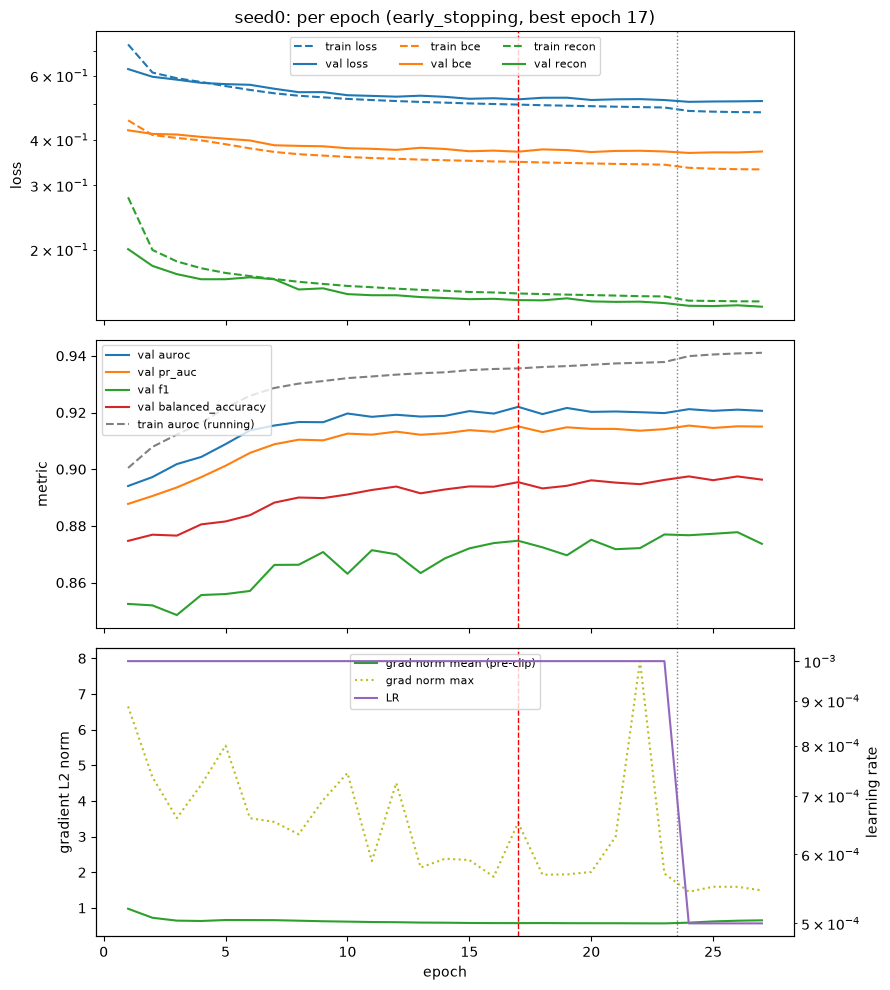

2026-11-03T10:05:20 checks: labels 0 / 1 with both classes in train and val, label names agree, GridSybil only from the GridSybil folders; no shared vehicle key; one label per track
2026-11-03T10:05:21 train 779,087 / val 67,582 windows (14s to load), shape (32, 13) + mask; vehicles 5,933 / 524; tracks 622,303 / 54,404; classes {"train": {"benign": 535501, "gridsybil": 243586}, "val": {"benign": 47279, "gridsybil": 20303}}; pos_weight = n_benign / n_gridsybil (train) = 2.1984
2026-11-03T10:05:21 padding share train 0.492 / val 0.497
2026-11-03T10:05:21 windows per family x class: {"train": {"DataReplaySybil": {"benign": 133789, "gridsybil": 0}, "DoSDisruptiveSybil": {"benign": 133821, "gridsybil": 0}, "DoSRandomSybil": {"benign": 133821, "gridsybil": 0}, "GridSybil": {"benign": 134070, "gridsybil": 243586}}, "val": {"DataReplaySybil": {"benign": 12037, "gridsybil": 0}, "DoSDisruptiveSybil": {"benign": 12057, "gridsybil": 0}, "DoSRandomSybil": {"benign": 12057, "gridsybil": 0}, "GridSyb

In [8]:
print(json.dumps({k: v for k, v in summary.items() if k not in ("thresholds", "best_val", "family_counts")}, indent=2))
print("best epoch val metrics:", {k: round(v, 4) for k, v in summary["best_val"].items()})
history = pd.read_json(RUN / "history.jsonl", lines=True)
best = summary["best_epoch"]
print("epoch 1 val AUROC:", round(float(history.val_auroc.iloc[0]), 4))
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
for key, c in (("loss", "tab:blue"), ("bce", "tab:orange"), ("recon", "tab:green")):
    axes[0].plot(history.epoch, history[f"train_{key}"], color=c, ls="--", label=f"train {key}")
    axes[0].plot(history.epoch, history[f"val_{key}"], color=c, label=f"val {key}")
axes[0].set_yscale("log")
axes[0].set_ylabel("loss")
axes[0].legend(fontsize=8, ncol=3)
axes[0].set_title(f"{RUN.name}: per epoch ({summary['stop_reason']}, best epoch {best})")
for key in ("auroc", "pr_auc", "f1", "balanced_accuracy"):
    axes[1].plot(history.epoch, history[f"val_{key}"], label=f"val {key}")
axes[1].plot(history.epoch, history.train_auroc, color="grey", ls="--", label="train auroc (running)")
axes[1].set_ylabel("metric")
axes[1].legend(fontsize=8)
axes[2].plot(history.epoch, history.grad_norm_mean, color="tab:green", label="grad norm mean (pre-clip)")
axes[2].plot(history.epoch, history.grad_norm_max, color="tab:olive", ls=":", label="grad norm max")
axes[2].set_ylabel("gradient L2 norm")
axes[2].set_xlabel("epoch")
lr_ax = axes[2].twinx()
lr_ax.plot(history.epoch, history.lr, color="tab:purple", label="LR")
lr_ax.set_yscale("log")
lr_ax.set_ylabel("learning rate")
for a in axes:
    for c in summary["lr_changes"]:
        a.axvline(c["after_epoch"] + 0.5, color="grey", ls=":", lw=1)
    a.axvline(best, color="red", ls="--", lw=1)
h1, l1 = axes[2].get_legend_handles_labels()
h2, l2 = lr_ax.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, fontsize=8)
fig.tight_layout()
plt.show()

log = (RUN / "train.log").read_text().splitlines()
ep = [l for l in log if re.search(r" epoch +\d+ ", l)]
head = [l for l in log if " epoch " not in l and "lr reduced" not in l][:5]
print(
    "\n".join(
        head
        + ["..."]
        + ep[:3]
        + ["..."]
        + [l for l in ep if "*best" in l][-2:]
        + ["..."]
        + [l for l in log if "lr reduced" in l]
        + ["..."]
        + [l for l in log if "early stopping:" in l]
    )
)

The two alarm thresholds, both picked on the **val** split by `train.py` (window level, and per track on the max /
mean of the window probabilities): max F1 on val, and the 95th percentile of the benign val probabilities (benign
FPR 5% on val). Recomputed here from `best.pt` on val and compared with the summary.

In [9]:
trainer = Trainer.from_checkpoint(RUN / "best.pt")
cfg = trainer.settings
val_out = trainer.predict(val.x, val.mask)
thr_win = val_thresholds(val.y, val_out["prob"], cfg.target_fpr)
same = all(np.isclose(thr_win[k]["threshold"], summary["thresholds"]["window"][k]["threshold"]) for k in thr_win)
print(
    "val AUROC of best.pt:",
    round(ranking_metrics(val.y, val_out["prob"])["auroc"], 5),
    "(run:",
    round(summary["best_val_auroc"], 5),
    ")",
)
print("window thresholds equal the run's summary:", same)
THR = summary["thresholds"]
pd.DataFrame(
    {
        k: {
            "threshold": v["threshold"],
            "val precision": v["precision"],
            "val recall": v["recall"],
            "val F1": v["f1"],
            "val benign FPR": v["benign_fpr"],
        }
        for k, v in THR["window"].items()
    }
).T.round(4)

val AUROC of best.pt: 0.92201 (run: 0.92201 )
window thresholds equal the run's summary: True


,threshold,val precision,val recall,val F1,val benign FPR
max_f1,0.5958,0.9737,0.8012,0.8791,0.0093
benign_fpr_5pct,0.2960,0.8767,0.8280,0.8517,0.0500


## 4. Test

**Scoring first, labels after.** Every test window gets its GridSybil probability, reconstruction error and z from
`best.pt` (inputs: x and mask only). Per-track scores are the max and mean of the window probabilities.

In [10]:
test_out = trainer.predict(test.x, test.mask)
test_track = tracks["test"].aggregate(test_out["prob"])
print(
    f"scored {len(test):,} test windows in {len(tracks['test']):,} tracks; prob range "
    f"[{test_out['prob'].min():.4f}, {test_out['prob'].max():.4f}]"
)

scored 67,100 test windows in 54,102 tracks; prob range [0.0057, 1.0000]


Labels are read now (GridSybil = positive). Track label = majority of its windows; mixed tracks are counted.

In [11]:
y_win = test.y.astype(int)
y_trk, mixed = tracks["test"].track_labels(y_win)
print(f"tracks whose windows disagree on the label: {mixed}")
print(f"windows: benign {int((y_win == 0).sum()):,}, GridSybil {int(y_win.sum()):,} (share {y_win.mean():.3f})")
print(f"tracks:  benign {int((y_trk == 0).sum()):,}, GridSybil {int(y_trk.sum()):,} (share {y_trk.mean():.3f})")

tracks whose windows disagree on the label: 0
windows: benign 45,448, GridSybil 21,652 (share 0.323)
tracks:  benign 36,316, GridSybil 17,786 (share 0.329)


AUROC, PR-AUC (chance = GridSybil share) and precision / recall / F1 / balanced accuracy / benign FPR at the two val
thresholds, per window and per track (max / mean). Also the plain 0.5 threshold, for reference.

In [12]:
levels = {
    "window": (y_win, test_out["prob"], THR["window"]),
    "track max": (y_trk, test_track["max"], THR["track"]["max"]),
    "track mean": (y_trk, test_track["mean"], THR["track"]["mean"]),
}
rows = []
for level, (y, s, thr) in levels.items():
    base = {"level": level, **ranking_metrics(y, s), "chance": y.mean()}
    picks = {**{k: v["threshold"] for k, v in thr.items()}, "fixed 0.5": 0.5}
    for name, t in picks.items():
        m = threshold_metrics(y, s, t)
        rows.append(
            {
                **base,
                "threshold": name,
                "θ": t,
                **{k: m[k] for k in ("precision", "recall", "f1", "balanced_accuracy", "benign_fpr")},
                **m["confusion"],
            }
        )
res = pd.DataFrame(rows)
display(res.drop(columns=["tn", "fp", "fn", "tp"]).set_index(["level", "threshold"]).round(4))

auroc  pr_auc  chance       θ  precision  recall  \
level      threshold                                                            
window     max_f1           0.9263  0.9248  0.3227  0.5958     0.9721  0.8192   
           benign_fpr_5pct  0.9263  0.9248  0.3227  0.2960     0.8936  0.8389   
           fixed 0.5        0.9263  0.9248  0.3227  0.5000     0.9538  0.8233   
track max  max_f1           0.9248  0.9240  0.3287  0.6435     0.9716  0.8152   
           benign_fpr_5pct  0.9248  0.9240  0.3287  0.3373     0.8936  0.8350   
           fixed 0.5        0.9248  0.9240  0.3287  0.5000     0.9444  0.8227   
track mean max_f1           0.9269  0.9255  0.3287  0.5259     0.9682  0.8174   
           benign_fpr_5pct  0.9269  0.9255  0.3287  0.2857     0.8912  0.8387   
           fixed 0.5        0.9269  0.9255  0.3287  0.5000     0.9640  0.8190   

                                f1  balanced_accuracy  benign_fpr  
level      threshold                                               
window     max_f1           0.8891             0.9040      0.0112  
           benign_fpr_5pct  0.8654             0.8956      0.0476  
           fixed 0.5        0.8838             0.9022      0.0190  
track max  max_f1           0.8865             0.9018      0.0117  
           benign_fpr_5pct  0.8633             0.8932      0.0487  
           fixed 0.5        0.8794             0.8995      0.0237  
track mean max_f1           0.8865             0.9022      0.0131  
           benign_fpr_5pct  0.8641             0.8943      0.0502  
           fixed 0.5        0.8856             0.9020      0.0150

Confusion matrices per window at the two val thresholds (rows = truth, columns = prediction).

In [13]:
for _, r in res[(res.level == "window") & (res.threshold != "fixed 0.5")].iterrows():
    cm = pd.DataFrame(
        [[r.tn, r.fp], [r.fn, r.tp]], index=["true benign", "true GridSybil"], columns=["pred benign", "pred GridSybil"]
    )
    print(f"{r.threshold} (θ = {r['θ']:.4f})")
    display(cm)

max_f1 (θ = 0.5958)


,pred benign,pred GridSybil
true benign,44939,509
true GridSybil,3914,17738


benign_fpr_5pct (θ = 0.2960)


,pred benign,pred GridSybil
true benign,43285,2163
true GridSybil,3489,18163


ROC and precision-recall curves (window and track max), with the two val thresholds marked on the window curves.

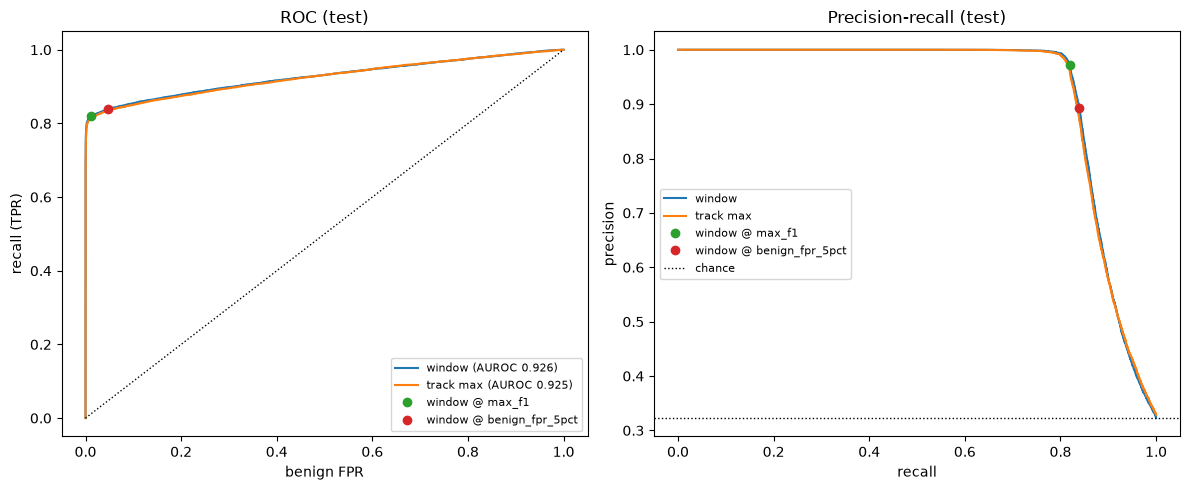

In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
for level in ("window", "track max"):
    y, s, _ = levels[level]
    fpr, tpr, _ = roc_curve(y, s)
    p, r, _ = precision_recall_curve(y, s)
    a1.plot(fpr, tpr, label=f"{level} (AUROC {roc_auc_score(y, s):.3f})")
    a2.plot(r, p, label=level)
for name, v in THR["window"].items():
    m = threshold_metrics(y_win, test_out["prob"], v["threshold"])
    a1.plot(m["benign_fpr"], m["recall"], "o", label=f"window @ {name}")
    a2.plot(m["recall"], m["precision"], "o", label=f"window @ {name}")
a1.plot([0, 1], [0, 1], "k:", lw=1)
a1.set_xlabel("benign FPR")
a1.set_ylabel("recall (TPR)")
a1.legend(fontsize=8)
a2.axhline(y_win.mean(), color="k", ls=":", lw=1, label="chance")
a2.set_xlabel("recall")
a2.set_ylabel("precision")
a2.legend(fontsize=8)
a1.set_title("ROC (test)")
a2.set_title("Precision-recall (test)")
fig.tight_layout()
plt.show()

Test probability histogram by class, with the two val thresholds.

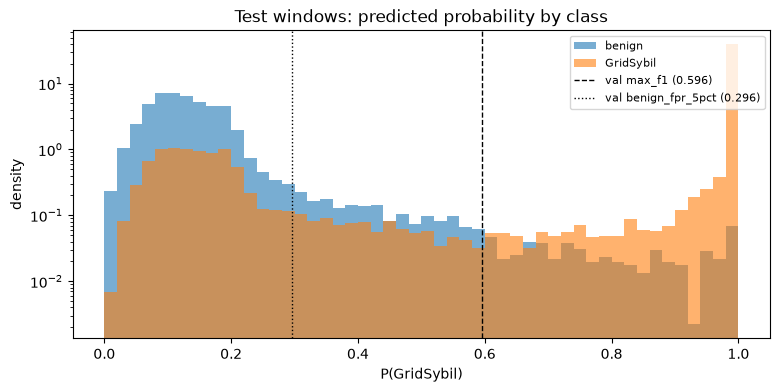

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 51)
ax.hist(test_out["prob"][y_win == 0], bins=bins, alpha=0.6, density=True, label="benign")
ax.hist(test_out["prob"][y_win == 1], bins=bins, alpha=0.6, density=True, label="GridSybil")
for (name, v), ls in zip(THR["window"].items(), ("--", ":")):
    ax.axvline(v["threshold"], color="black", ls=ls, lw=1, label=f"val {name} ({v['threshold']:.3f})")
ax.set_yscale("log")
ax.set_xlabel("P(GridSybil)")
ax.set_ylabel("density")
ax.legend(fontsize=8)
ax.set_title("Test windows: predicted probability by class")
plt.show()

Length shortcut check: test AUROC by window length (real messages), the length-only AUROC (best direction) for
reference, and the AUROC on windows with at least 4 real rows.

In [16]:
def length_auroc(y, n):
    a = roc_auc_score(y, n)
    return max(a, 1 - a)


groups = [(1, 3), (4, 16), (17, 31), (32, 32), (4, 32)]
rows = []
for lo, hi in groups:
    s = (test.n_messages >= lo) & (test.n_messages <= hi)
    y = y_win[s]
    rows.append(
        {
            "real rows": f"{lo}-{hi}",
            "windows": int(s.sum()),
            "GridSybil share": round(y.mean(), 3),
            "AUROC": roc_auc_score(y, test_out["prob"][s]),
            "length-only AUROC (best direction)": length_auroc(y, test.n_messages[s]) if lo != hi else float("nan"),
        }
    )
print("length-only AUROC, all test windows (best direction):", round(length_auroc(y_win, test.n_messages), 4))
by_length = pd.DataFrame(rows).set_index("real rows").round(4)
by_length

length-only AUROC, all test windows (best direction): 0.5599


,windows,GridSybil share,AUROC,length-only AUROC (best direction)
real rows,,,,
1-3,10585,0.416,0.9149,0.5201
4-16,27057,0.333,0.9225,0.5355
17-31,15860,0.265,0.9125,0.5261
32-32,13598,0.296,0.9300,NaN
4-32,56515,0.305,0.9240,0.5372


**Benign windows by scenario folder.** The benign traffic of the DataReplay / DoS folders never appears with a
GridSybil label, so: do benign windows from those folders get false alarms more often than benign windows from the
GridSybil folders? Per folder: benign test windows, mean P(GridSybil), benign FPR at both val thresholds, and the
AUROC of the test GridSybil windows of the same period against that folder's benign windows.

In [17]:
scen = np.asarray(test.info["scenario"])
period = np.asarray([s.rsplit("_", 1)[-1] for s in scen])
rows = []
for sc in sorted(set(scen[y_win == 0])):
    b = (scen == sc) & (y_win == 0)
    g = (period == sc.rsplit("_", 1)[-1]) & (y_win == 1)
    row = {
        "folder": sc,
        "benign test windows": int(b.sum()),
        "share 1-3 rows": round(float((test.n_messages[b] <= 3).mean()), 3),
        "mean P(GridSybil)": test_out["prob"][b].mean(),
    }
    for name, v in THR["window"].items():
        row[f"benign FPR @ {name}"] = float((test_out["prob"][b] >= v["threshold"]).mean())
    sb, sg = test_out["prob"][b], test_out["prob"][g]
    row["AUROC vs same-period GridSybil"] = roc_auc_score(np.r_[np.zeros(len(sb)), np.ones(len(sg))], np.r_[sb, sg])
    rows.append(row)
by_folder = pd.DataFrame(rows).set_index("folder").round(4)
by_folder

,benign test windows,share 1-3 rows,mean P(GridSybil),benign FPR @ max_f1,benign FPR @ benign_fpr_5pct,AUROC vs same-period GridSybil
folder,,,,,,
DataReplaySybil_0709,8799,0.135,0.1458,0.0108,0.0492,0.9263
DataReplaySybil_1416,2351,0.133,0.1474,0.0128,0.0536,0.9249
DoSDisruptiveSybil_0709,8821,0.139,0.1445,0.0105,0.0463,0.9268
DoSDisruptiveSybil_1416,2347,0.133,0.1477,0.0119,0.0533,0.9250
DoSRandomSybil_0709,8821,0.139,0.1445,0.0105,0.0463,0.9268
DoSRandomSybil_1416,2347,0.133,0.1477,0.0124,0.0528,0.9250
GridSybil_0709,9611,0.133,0.1443,0.0110,0.0431,0.9267
GridSybil_1416,2351,0.137,0.1476,0.0149,0.0532,0.9253


**Per period** (0709 vs 1416): all test windows of one period (benign from its four folders + its GridSybil windows).
GridSybil_0709 is the 2025 re-simulation of the 0709 traffic (F14).

In [18]:
rows = []
for p in ("0709", "1416"):
    s = period == p
    y, sc = y_win[s], test_out["prob"][s]
    row = {"period": p, "windows": int(s.sum()), "GridSybil share": round(y.mean(), 3), **ranking_metrics(y, sc)}
    for name, v in THR["window"].items():
        m = threshold_metrics(y, sc, v["threshold"])
        row[f"F1 @ {name}"] = m["f1"]
        row[f"recall @ {name}"] = m["recall"]
        row[f"benign FPR @ {name}"] = m["benign_fpr"]
    rows.append(row)
by_period = pd.DataFrame(rows).set_index("period").round(4)
by_period

,windows,GridSybil share,auroc,pr_auc,F1 @ max_f1,recall @ max_f1,benign FPR @ max_f1,F1 @ benign_fpr_5pct,recall @ benign_fpr_5pct,benign FPR @ benign_fpr_5pct
period,,,,,,,,,,
0709,52961,0.319,0.9267,0.9242,0.8879,0.8167,0.0107,0.8651,0.8373,0.0461
1416,14139,0.335,0.9251,0.9270,0.8936,0.8284,0.0130,0.8661,0.8444,0.0532


Mean per-feature reconstruction error by class on the test windows, and the per-feature AUROC of that error.

In [19]:
ef = test_out["error_feature"]
print(
    f"mean window reconstruction error: benign {test_out['error'][y_win == 0].mean():.4f}, "
    f"GridSybil {test_out['error'][y_win == 1].mean():.4f}; "
    f"AUROC of the error {roc_auc_score(y_win, test_out['error']):.4f}"
)
pd.DataFrame(
    {
        "benign": ef[y_win == 0].mean(0),
        "GridSybil": ef[y_win == 1].mean(0),
        "AUROC": [roc_auc_score(y_win, ef[:, j]) for j in range(ef.shape[1])],
    },
    index=FEATURES,
).round(4).sort_values("AUROC", ascending=False)

mean window reconstruction error: benign 0.1458, GridSybil 0.2023; AUROC of the error 0.5975


,benign,GridSybil,AUROC
log_dtau,0.2081,0.5519,0.6909
range,0.0327,0.1095,0.6751
claimed_pos_y,0.0203,0.0561,0.6598
claimed_pos_x,0.0220,0.0613,0.6295
bearing,0.1393,0.2283,0.6008
rx_pos_y,0.0255,0.0402,0.5854
rx_pos_x,0.0216,0.0355,0.5765
rx_vel_x,0.1381,0.1689,0.5386
rx_vel_y,0.1196,0.1438,0.5375
claimed_acl_y,0.4379,0.5408,0.5261


## 5. Comparison (context only)

Other numbers on GridSybil from this repo. The setups differ (data cut, T, split, metric unit, seeds), so these rows
are context, not a controlled comparison: `task/autoencoder_st` (supervised, T48_tvt, benign + GridSybil of the
GridSybil folders only, window AUROC), `task/autoencoder_benign_t32` (one-class, benign-only training, all/T32_benign
test_gridsybil vs benign test, window AUROC), and the VeReMi-Extension paper's plausibility detector re-implemented in
`src/baselines/plausibility/` (CaTCh checks, **per received message F1**, not a window AUROC).

In [20]:
w = res[(res.level == "window")].iloc[0]
w_f1 = res[(res.level == "window") & (res.threshold == "max_f1")]
cmp = [
    {
        "run": f"this run ({RUN.name}): supervised AE + head, all/T32_benign_grid",
        "unit": "window",
        "metric": "AUROC / F1 @ val max-F1",
        "value": f"{w.auroc:.3f} / {float(w_f1.f1.iloc[0]):.3f}" if len(w_f1) else f"{w.auroc:.3f}",
        "seeds": 1,
    },
    {
        "run": "task/autoencoder_st seed0: supervised AE + head, T48_tvt",
        "unit": "window",
        "metric": "AUROC",
        "value": "0.929",
        "seeds": 1,
    },
    {
        "run": "task/autoencoder_benign_t32 seed0: one-class AE, all/T32_benign (GridSybil test)",
        "unit": "window",
        "metric": "AUROC (reconstruction)",
        "value": "0.736",
        "seeds": 1,
    },
    {
        "run": "plausibility baseline (paper Table III, CaTCh), GridSybil 0709 / 1416",
        "unit": "received message",
        "metric": "F1",
        "value": "0.727 / 0.692",
        "seeds": "-",
    },
]
pd.DataFrame(cmp).set_index("run")

,unit,metric,value,seeds
run,,,,
"this run (seed0): supervised AE + head, all/T32_benign_grid",window,AUROC / F1 @ val max-F1,0.926 / 0.889,1
"task/autoencoder_st seed0: supervised AE + head, T48_tvt",window,AUROC,0.929,1
"task/autoencoder_benign_t32 seed0: one-class AE, all/T32_benign (GridSybil test)",window,AUROC (reconstruction),0.736,1
"plausibility baseline (paper Table III, CaTCh), GridSybil 0709 / 1416",received message,F1,0.727 / 0.692,-


The numbers the analysis below refers to.

In [21]:
results = {
    "run": RUN.name,
    "params": summary["params"],
    "best_epoch": summary["best_epoch"],
    "best_val_auroc": round(summary["best_val_auroc"], 4),
    "epoch1_val_auroc": round(float(history.val_auroc.iloc[0]), 4),
    "epochs_run": summary["epochs_run"],
    "stop_reason": summary["stop_reason"],
    "lr_changes": len(summary["lr_changes"]),
    "train_minutes": round(summary["train_seconds"] / 60, 1),
    "pos_weight": round(summary["pos_weight"], 4),
    "mixed_label_tracks": mixed,
    "test_windows": len(test),
    "test_tracks": len(tracks["test"]),
    "test_gridsybil_share": round(float(y_win.mean()), 4),
    "length_only_auroc": round(length_auroc(y_win, test.n_messages), 4),
    "reconstruction_error_auroc": round(roc_auc_score(y_win, test_out["error"]), 4),
}
for _, r in res.iterrows():
    results[f"{r.level}/{r.threshold}"] = {
        k: round(float(r[k]), 4)
        for k in ("auroc", "pr_auc", "θ", "precision", "recall", "f1", "balanced_accuracy", "benign_fpr")
    }
results

{'run': 'seed0',
 'params': 63870,
 'best_epoch': 17,
 'best_val_auroc': 0.922,
 'epoch1_val_auroc': 0.8941,
 'epochs_run': 27,
 'stop_reason': 'early_stopping',
 'lr_changes': 1,
 'train_minutes': 5.6,
 'pos_weight': 2.1984,
 'mixed_label_tracks': 0,
 'test_windows': 67100,
 'test_tracks': 54102,
 'test_gridsybil_share': 0.3227,
 'length_only_auroc': 0.5599,
 'reconstruction_error_auroc': 0.5975,
 'window/max_f1': {'auroc': 0.9263,
  'pr_auc': 0.9248,
  'θ': 0.5958,
  'precision': 0.9721,
  'recall': 0.8192,
  'f1': 0.8891,
  'balanced_accuracy': 0.904,
  'benign_fpr': 0.0112},
 'window/benign_fpr_5pct': {'auroc': 0.9263,
  'pr_auc': 0.9248,
  'θ': 0.296,
  'precision': 0.8936,
  'recall': 0.8389,
  'f1': 0.8654,
  'balanced_accuracy': 0.8956,
  'benign_fpr': 0.0476},
 'window/fixed 0.5': {'auroc': 0.9263,
  'pr_auc': 0.9248,
  'θ': 0.5,
  'precision': 0.9538,
  'recall': 0.8233,
  'f1': 0.8838,
  'balanced_accuracy': 0.9022,
  'benign_fpr': 0.019},
 'track max/max_f1': {'auroc': 0.92

## 6. Analysis

Numbers from the outputs above (run `seed0`, one seed, no confidence intervals).

- **Training was short and stopped on val.** Val AUROC was 0.894 at epoch 1 (no sign of leakage: not near 1.0;
  inputs are x + mask only) and reached its best, **0.9220, at epoch 17**; one LR halving after epoch 23 did not help
  and early stopping (patience 10, min_delta 1e-4) ended the run at epoch 27, 5.6 min on MPS. At the best epoch the
  running train AUROC was 0.936 vs val 0.922 (train measured in train mode, indicative only). `pos_weight` =
  535,501 / 243,586 = 2.198 from the train counts (GridSybil is 31% of train windows here, vs 64% in T48_tvt).
- **Test, per window** (67,100 windows, GridSybil share 0.323; labels read after scoring): AUROC **0.926**, PR-AUC
  **0.925** (chance 0.323). At the val max-F1 threshold (θ = 0.596): precision 0.972, recall 0.819, F1 **0.889**,
  balanced accuracy 0.904, benign FPR 0.011. At the val benign-FPR-5% threshold (θ = 0.296): benign FPR 0.048
  (nominal 0.05), recall 0.839, F1 0.865. Both val thresholds carry over to test closely. About 16-18% of GridSybil
  test windows are missed at either threshold.
- **Per track** (54,102 tracks, no mixed-label track): AUROC 0.925 (max) / 0.927 (mean), F1 about 0.89; most tracks
  hold one window, so aggregation changes little.
- **Not a length shortcut:** length alone gives AUROC 0.560. The model reaches 0.915 on 1-3-row windows, 0.924 on
  windows with ≥ 4 rows and 0.930 on full 32-row windows.
- **Benign windows from DataReplay / DoS folders are not flagged more often.** Their benign test FPR at the val max-F1
  threshold is 0.011-0.013, the same as the GridSybil folders' benign windows (0.011 / 0.015); mean P(GridSybil)
  is 0.144-0.148 in every folder, and each folder's benign windows separate from the same-period GridSybil windows
  equally (AUROC 0.925-0.927). This is expected rather than reassuring: the four families of one period share the same
  benign traffic (F1; DoSRandom and DoSDisruptive benign counts are identical), so the extra folders add mostly copies
  of the same benign cars, not new benign behaviour.
- **Per period:** 0709 AUROC 0.927, F1 0.888; 1416 AUROC 0.925, F1 0.894. No period gap at this level, although
  GridSybil_0709 is the 2025 re-simulation (F14).
- **The head does the detecting.** The window reconstruction error alone has AUROC 0.598 (higher than the 0.478 of the
  T48 supervised run): GridSybil is rebuilt worse on log-Δτ, range and claimed position (AUROC 0.63-0.69) and better on
  claimed velocity (0.34-0.37).
- **Context (different setups, not controlled):** about the level of `task/autoencoder_st` on T48_tvt (0.929), with a
  harder benign side (benign from all 8 folders, 69% of windows) and T = 32. Far above the one-class T32 autoencoder on
  GridSybil (0.736 reconstruction AUROC; no labels). The plausibility baseline's GridSybil F1 0.727 / 0.692 is per
  received message, not per window, so it is not comparable with the window F1 0.889 here.
- **Limits:** one seed; windows of one vehicle are not independent (524 test vehicle keys), so no CI is claimed. F14:
  GridSybil_0709 near-copies of other 0709 cars may straddle the split (not measured here). F1: benign traffic repeats
  across the four families of a period, which inflates the benign window count, not the information. GridSybil is the
  only attack in training and test, so this says nothing about unseen attacks (DataReplay / DoS). Track ids contain
  the true sender (F13, privileged grouping). Not the thesis TimesNet model and not a thesis result.